# Étape 3 & 4: Brain Tumor Classification with Transfer Learning (MobileNetV2)
- Load preprocessed datasets (Train, Val, Test).
- Build MobileNetV2 with a custom 4-class head.
- Phase 1: Train top layers (frozen base).
- Phase 2: Fine-tune top layers with low learning rate.
- Overfitting prevention: Dropout, EarlyStopping, ReduceLROnPlateau, ModelCheckpoint.

## 1. Setup, Imports & Dataset Loading

In [12]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt 
import tensorflow as tf


DATA_DIR = Path('../data')
  
IMG_SIZE = (224, 224)
  
BATCH_SIZE = 32
  
AUTOTUNE = tf.data.AUTOTUNE

IMG_SIZE = (224, 224)

BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / 'Train' ,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=True)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / 'Val' ,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / 'Test' ,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False)

class_names = train_ds.class_names

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print(class_names)

Found 2651 files belonging to 4 classes.
Found 969 files belonging to 4 classes.
Found 293 files belonging to 4 classes.
['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


## 2. Building MobileNetV2 Transfer Learning Architecture
- Load pretrained MobileNetV2 backbone (ImageNet weights, include_top=False).
- Freeze pretrained base layers (Phase 1: Feature Extraction).
- Attach custom head: GlobalAveragePooling2D, Dense (L2), Dropout(0.3), Softmax(4).

In [13]:
# load pretrained base model with imagenet weights
base_model = tf.keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')

# freeze the base model layers
base_model.trainable = False

# data augmentation layers
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
    tf.keras.layers.RandomContrast(0.1),
], name='data_augmentation')

# input layer
inputs = tf.keras.Input(shape=(224, 224, 3))

# apply data augmentation on the fly
x = data_augmentation(inputs)

# scale pixel values
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

# pass through frozen base
x = base_model(x, training=False)

# pool features to a vector
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# dense layer with weight regularization
x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)

# randomly drop connections to reduce overfitting
x = tf.keras.layers.Dropout(0.3)(x)

# final prediction layer for classes
outputs = tf.keras.layers.Dense(4, activation='softmax')(x)

# combine inputs and outputs into final model
model = tf.keras.Model(inputs, outputs)

model.summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 3. Training Callbacks & Model Compilation (Phase 1)
- EarlyStopping: stops training when val_loss stagnates for 5 epochs.
- ModelCheckpoint: saves the best model to models/best_mobilenet_phase1.keras.
- ReduceLROnPlateau: cuts learning rate when progress slows down.
- Compile model: Adam optimizer (lr=0.001) with categorical crossentropy.

In [14]:
# create directory for saved models
os.makedirs('../models', exist_ok=True)

# list of training callbacks
callbacks = [
    # stop training when validation loss stops improving
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),
    # save the best model weights
    tf.keras.callbacks.ModelCheckpoint(
        filepath='../models/best_mobilenet_phase1.keras',
        monitor='val_loss',
        save_best_only=True
    ),
    # reduce learning rate when progress slows down
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-6
    )
]

# compile model with adam optimizer and loss function
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("model compiled with callbacks ready")


model compiled with callbacks ready


## 4. Phase 1 Training: Feature Extraction (Frozen Base)
- Train the custom classification head for 15 epochs.
- Base model remains frozen.
- Callbacks monitor val_loss, save the best weights, and apply early stopping.

In [15]:
EPOCHS = 15


history_phase1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/15


/home/emad/Desktop/AI projects/IRM detection/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


83/83 ━━━━━━━━━━━━━━━━━━━━ 63s 739ms/step - accuracy: 0.7480 - loss: 0.8155 - val_accuracy: 0.7534 - val_loss: 0.7988 - learning_rate: 0.0010
Epoch 2/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 68s 816ms/step - accuracy: 0.8619 - loss: 0.5446 - val_accuracy: 0.7307 - val_loss: 0.9741 - learning_rate: 0.0010
Epoch 3/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 65s 789ms/step - accuracy: 0.8684 - loss: 0.5097 - val_accuracy: 0.7193 - val_loss: 0.9595 - learning_rate: 0.0010
Epoch 4/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 58s 704ms/step - accuracy: 0.8895 - loss: 0.4508 - val_accuracy: 0.7616 - val_loss: 0.8200 - learning_rate: 0.0010
Epoch 5/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 65s 789ms/step - accuracy: 0.9197 - loss: 0.3752 - val_accuracy: 0.7915 - val_loss: 0.7023 - learning_rate: 2.0000e-04
Epoch 6/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 74s 899ms/step - accuracy: 0.9215 - loss: 0.3632 - val_accuracy: 0.8101 - val_loss: 0.6373 - learning_rate: 2.0000e-04
Epoch 7/15
83/83 ━━━━━━━━━━━━━━━━━━━━ 74s 892ms/step - accuracy: 0.9219 - loss: 0.346

## 5. Learning Curves Analysis (Phase 1)
- Plot training vs validation accuracy.
- Plot training vs validation loss.
- Inspect curves to verify healthy convergence without severe overfitting.

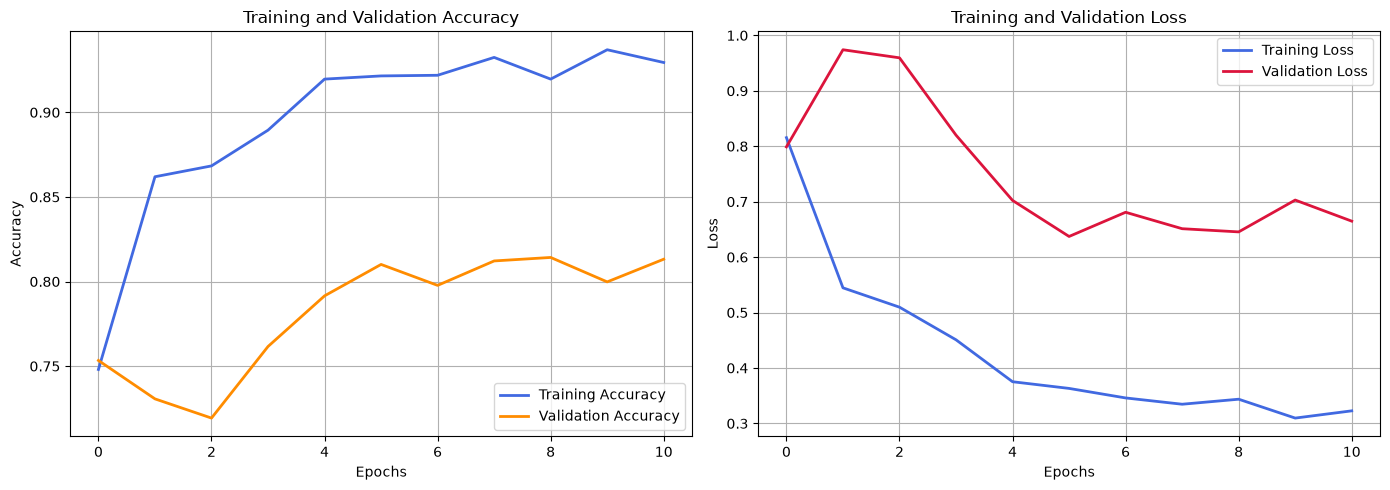

In [16]:
# extract training metrics
acc = history_phase1.history['accuracy']
val_acc = history_phase1.history['val_accuracy']
loss = history_phase1.history['loss']
val_loss = history_phase1.history['val_loss']

# range of epochs for x axis
epochs_range = range(len(acc))

# create side by side figure
plt.figure(figsize=(14, 5))

# accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', color='royalblue', linewidth=2)
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='darkorange', linewidth=2)
plt.title('Training and Validation Accuracy', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', color='royalblue', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', color='crimson', linewidth=2)
plt.title('Training and Validation Loss', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()


## 6. Phase 2: Fine-Tuning (Unfreezing Top Layers)
- Unfreeze the base model, but keep all layers frozen except the last 30 layers.
- Recompile with a very low learning rate (1e-5).
- Update checkpoint to save models/best_mobilenet_fine_tuned.keras.

In [17]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
              loss='categorical_crossentropy', 
                metrics=['accuracy'])

callbacks_fine_tune = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath='../models/best_mobilenet_fine_tuned.keras',
        monitor='val_loss',
        save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7
    )
]

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 1,690,884 (6.45 MB)

 Non-trainable params: 731,584 (2.79 MB)

## 7. Phase 2 Training: Fine-Tuning Execution
- Train the unfrozen layers for 10 additional epochs.
- Uses low learning rate (1e-5) to adapt deep filters without destroying weights.
- Saves best weights to models/best_mobilenet_fine_tuned.keras.

In [18]:
EPOCHS_FINE_TUNE = 10

history_phase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE_TUNE,
    callbacks=callbacks_fine_tune
)

Epoch 1/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 76s 881ms/step - accuracy: 0.9219 - loss: 0.3536 - val_accuracy: 0.8349 - val_loss: 0.5747 - learning_rate: 1.0000e-05
Epoch 2/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 68s 826ms/step - accuracy: 0.9280 - loss: 0.3374 - val_accuracy: 0.8328 - val_loss: 0.6019 - learning_rate: 1.0000e-05
Epoch 3/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 68s 817ms/step - accuracy: 0.9295 - loss: 0.3267 - val_accuracy: 0.8349 - val_loss: 0.5823 - learning_rate: 1.0000e-05
Epoch 4/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 68s 821ms/step - accuracy: 0.9393 - loss: 0.2966 - val_accuracy: 0.8411 - val_loss: 0.5877 - learning_rate: 1.0000e-05
Epoch 5/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 68s 818ms/step - accuracy: 0.9495 - loss: 0.2805 - val_accuracy: 0.8318 - val_loss: 0.6267 - learning_rate: 2.0000e-06
Epoch 6/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 67s 808ms/step - accuracy: 0.9461 - loss: 0.2840 - val_accuracy: 0.8029 - val_loss: 0.7056 - learning_rate: 2.0000e-06


## 8. Configuration Comparison: Phase 1 vs Phase 2 Curves
- Combine training history from Phase 1 and Phase 2.
- Plot continuous accuracy and loss trajectories.
- Dotted vertical line marks the transition to fine-tuning.


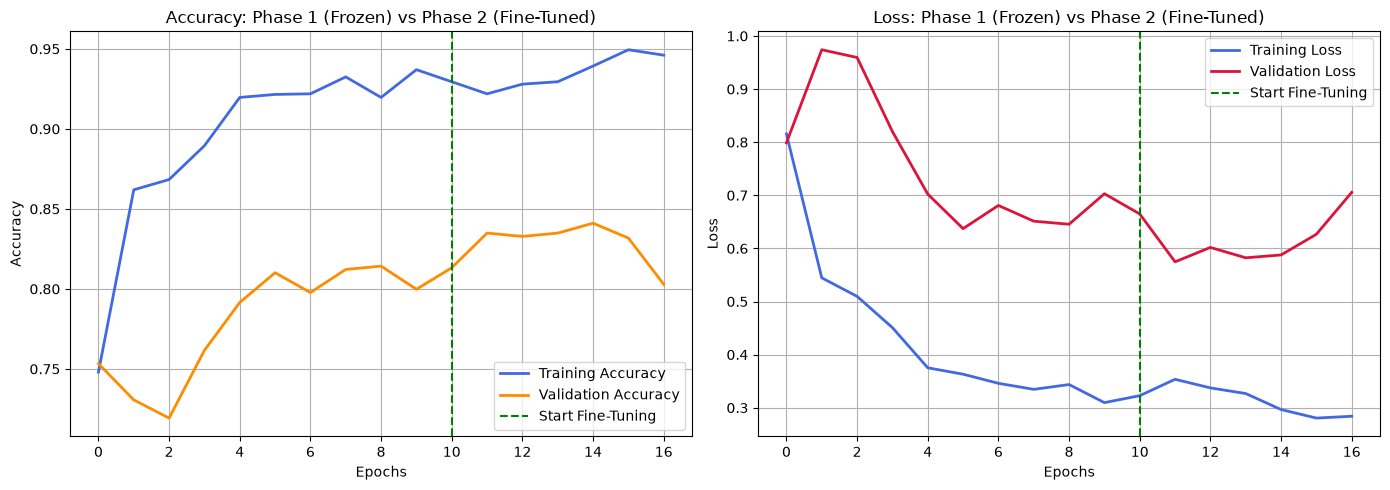

In [19]:
# combine metrics from both training configurations
acc_total = history_phase1.history['accuracy'] + history_phase2.history['accuracy']
val_acc_total = history_phase1.history['val_accuracy'] + history_phase2.history['val_accuracy']
loss_total = history_phase1.history['loss'] + history_phase2.history['loss']
val_loss_total = history_phase1.history['val_loss'] + history_phase2.history['val_loss']

# split point between frozen base and fine tuning
split_epoch = len(history_phase1.history['loss']) - 1

# create side by side comparison plots
plt.figure(figsize=(14, 5))

# accuracy trajectory plot
plt.subplot(1, 2, 1)
plt.plot(acc_total, label='Training Accuracy', color='royalblue', linewidth=2)
plt.plot(val_acc_total, label='Validation Accuracy', color='darkorange', linewidth=2)
plt.axvline(x=split_epoch, color='green', linestyle='--', label='Start Fine-Tuning')
plt.title('Accuracy: Phase 1 (Frozen) vs Phase 2 (Fine-Tuned)', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# loss trajectory plot
plt.subplot(1, 2, 2)
plt.plot(loss_total, label='Training Loss', color='royalblue', linewidth=2)
plt.plot(val_loss_total, label='Validation Loss', color='crimson', linewidth=2)
plt.axvline(x=split_epoch, color='green', linestyle='--', label='Start Fine-Tuning')
plt.title('Loss: Phase 1 (Frozen) vs Phase 2 (Fine-Tuned)', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()


## 9. Final Model Evaluation on the Test Set (Étape 6)
- Load best fine-tuned model checkpoint from disk.
- Compute Accuracy, Precision, Recall, and F1-score across all 4 classes.
- Plot the Confusion Matrix heatmap to analyze misclassifications.


10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 540ms/step - accuracy: 0.8601 - loss: 0.5144
test accuracy: 0.8601
test loss: 0.5144
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 525ms/step

classification report:
              precision    recall  f1-score   support

      Glioma       0.88      0.90      0.89        86
  Meningioma       0.87      0.72      0.79        83
    No Tumor       0.88      0.84      0.86        45
   Pituitary       0.83      0.97      0.90        79

    accuracy                           0.86       293
   macro avg       0.86      0.86      0.86       293
weighted avg       0.86      0.86      0.86       293



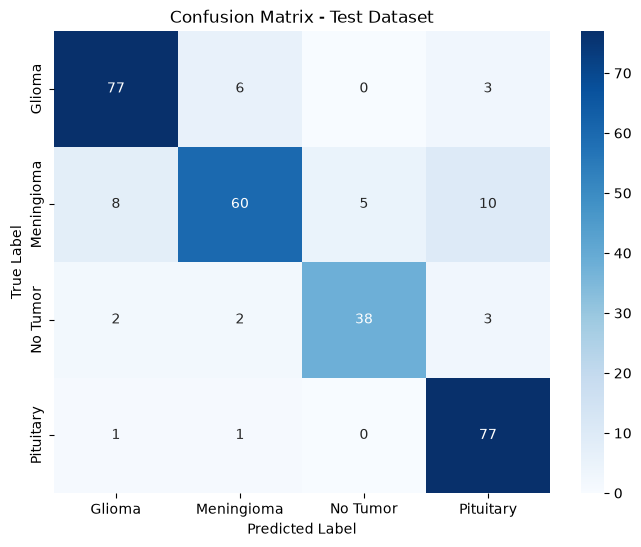

In [20]:
# import evaluation tools
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# load the best saved model from disk
best_model = tf.keras.models.load_model('../models/best_mobilenet_fine_tuned.keras')

# evaluate directly on untouched test dataset
test_loss, test_accuracy = best_model.evaluate(test_ds)
print(f"test accuracy: {test_accuracy:.4f}")
print(f"test loss: {test_loss:.4f}")

# get predictions and true labels
predictions_prob = best_model.predict(test_ds)
predictions = np.argmax(predictions_prob, axis=1)
true_labels = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])

# print precision recall and fscore report
print("\nclassification report:")
print(classification_report(true_labels, predictions, target_names=class_names))

# compute confusion matrix
cm = confusion_matrix(true_labels, predictions)

# plot confusion matrix heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Test Dataset', fontsize=12)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()
